Example 9: Biomass Depolymerization (Population Balance, run in reverse)

A port of ``lignin_depolymerization.py`` onto
:class:`kipetax.PopulationBalanceModel`. It is the fragmentation mirror of the
quantum-dot growth in Ex_8: the same population balance run backwards, lignin
breaking into aromatics instead of monomer condensing into particles.

Two processes decide every real valorization and compete here. Random scission
breaks bonds, so the mean chain length falls and monomer yield rises.
Recondensation is bimolecular coagulation, forming larger products and char and
collapsing the monomer yield. The state is the fragment distribution N(i, t)
over degree of polymerization i, PLUS one scalar, the recondensation extent Q,
which the class carries as the last entry of the flat state vector.

The observation is UV-Vis through a conjugation-length ruler,
lambda_peak(i) = 275 + 45 (1 - 1/i), and it is NON-ADDITIVE: recondensation
forms new C-C chromophores in a distinct ~380 nm band whose intensity tracks Q,
not any single fragment concentration. That band is the c_A c_B interaction term
this whole line of work started from, now standing for colored condensation
products. It is a known-spectrum column, so the observation stays bilinear.

Fitting the two rate constants (k_s, k_r) to the UV time series recovers the
kinetics, the molecular-weight distribution, the monomer yield, and the char. A
naive per-spectrum non-negative inversion, which cannot place the recondensation
band, dumps that intensity onto the fragment spectra and overestimates the
monomer yield.

NOTE: all data here is SYNTHETIC, generated by the model below.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_9_lignin_depolymerization.py`).

In [2]:
import numpy as np
import jax.numpy as jnp

from kipetax import PopulationBalanceModel

# ── Grid and constants (from the source demo) ──
K = 50
IVEC = np.arange(1, K + 1).astype(float)     # degree of polymerization
LAM = np.linspace(250.0, 450.0, 120)         # wavelength, nm
TF, NT = 40.0, 1500

KS_TRUE, KR_TRUE = 0.03, 0.5

# Conjugation size ruler and the two known spectral bands.
WFRAG, WREC, LREC, CREC = 25.0, 30.0, 380.0, 0.6
LPEAK = 275.0 + 45.0 * (1.0 - 1.0 / IVEC)                          # (K,)
FKER = np.exp(-(LAM[:, None] - LPEAK[None, :]) ** 2 / (2 * WFRAG ** 2))   # (n_lam, K)
RBAND = np.exp(-(LAM - LREC) ** 2 / (2 * WREC ** 2))              # (n_lam,)

# Initial fragment distribution: Gaussian at DP 35, mass-normalized.
N0 = np.exp(-(IVEC - 35.0) ** 2 / (2 * 4.0 ** 2))
N0 = N0 / np.sum(IVEC * N0)

T_OBS = np.array([2, 4, 6, 9, 13, 18, 25, 32, 40.0])
IDX = np.clip((T_OBS / TF * NT).astype(int), 0, NT - 1)

_IVEC = jnp.asarray(IVEC)
_FKER = jnp.asarray(FKER)
_RBAND = jnp.asarray(RBAND)
_IDX = jnp.asarray(IDX)

def step(state, t, p):
    """Scission + bimolecular recondensation. state = [N (K), Q (scalar)]."""
    ks, kr = p['ks'], p['kr']
    N = state[:K]
    S = jnp.sum(N)
    # Tail sum: tail[i] = sum_{j>i} N_j.
    cs = jnp.cumsum(N[::-1])[::-1]
    tail = jnp.concatenate([cs[1:], jnp.array([0.0])])
    # Random scission.
    death = ks * (_IVEC - 1) * N
    birth = 2 * ks * tail
    # Coagulation convolution.
    conv = jnp.convolve(N, N)
    gain = jnp.concatenate([jnp.array([0.0]), 0.5 * kr * conv[:K - 1]])
    loss = kr * N * S
    dN = birth - death + gain - loss
    dQ = 0.5 * kr * S * S
    return jnp.concatenate([dN, jnp.array([dQ])])

def observe(history, p):
    """UV-Vis = fragment absorbance (DP-weighted) + non-additive Q band."""
    N = history[:, :K][_IDX]                   # (n_obs, K)
    Q = history[:, K][_IDX]                    # (n_obs,)
    A_frag = (N * _IVEC) @ _FKER.T
    A_rec = CREC * Q[:, None] * _RBAND[None, :]
    return A_frag + A_rec

def build_model():
    pbm = PopulationBalanceModel('lignin')
    pbm.set_coordinate('i', IVEC)
    pbm.parameter('ks', value=0.05, bounds=(1e-3, 1.0))
    pbm.parameter('kr', value=0.2, bounds=(1e-3, 5.0))
    pbm.set_initial_state(jnp.concatenate([jnp.asarray(N0), jnp.array([0.0])]))
    pbm.set_dynamics(step, t_end=TF, nt=NT, scheme='rk4')
    pbm.set_observation(observe)
    return pbm

def monomer_and_char(N_rows):
    """Monomer yield (mass fraction in DP-1) and char (mass lost off-grid)."""
    mass = (N_rows * IVEC).sum(axis=1)
    monomer = N_rows[:, 0] / np.maximum(mass, 1e-12)
    char = 1.0 - mass
    return monomer, char

## Run the analysis

In [3]:
truth = build_model().simulate({'ks': KS_TRUE, 'kr': KR_TRUE})
A_true = np.asarray(observe(jnp.asarray(truth.state_history),
                            {'ks': KS_TRUE, 'kr': KR_TRUE}))
rng = np.random.default_rng(0)
A_data = A_true + 0.02 * A_true.max() * rng.standard_normal(A_true.shape)

In [4]:
print("Fitting scission + recondensation to the UV-Vis time series...")
pbm = build_model()
pbm.add_data(A_data)
ro = pbm.run_opt(verbose=True)

Fitting scission + recondensation to the UV-Vis time series...


/Users/jkitchin/Dropbox/projects/jax-kipet/notebooks/../kipetax/main_modules/population_balance.py:290: OptimizeWarning: Unknown solver options: disp
  res = minimize(scipy_obj, theta0, jac=True, method='L-BFGS-B',


PopulationBalance fit: status=optimal objective=3.9080e-01 iters=10 |proj grad|=3.00e-06
  ks           = 0.0296704
  kr           = 0.504587


In [5]:
print(f"\n  {'param':8s} {'true':>10s} {'estimated':>12s} {'error%':>9s}")
print(f"  {'-' * 42}")
for name, tv in [('ks', KS_TRUE), ('kr', KR_TRUE)]:
    ev = ro.P[name]
    print(f"  {name:8s} {tv:>10.4f} {ev:>12.4f} {abs(ev - tv) / tv * 100:>8.2f}%")


  param          true    estimated    error%
  ------------------------------------------
  ks           0.0300       0.0297     1.10%
  kr           0.5000       0.5046     0.92%


In [6]:
# Monomer yield: mechanism vs naive per-spectrum inversion.
N_true = np.asarray(truth.state_history)[:, :K][IDX]
N_fit = ro.state_history[:, :K][IDX]
# Naive: invert onto the DP-weighted fragment kernel, ignoring the Q band.
G = FKER * IVEC[None, :]
N_naive = PopulationBalanceModel.nnls_inversion(A_data, G)

In [7]:
mono_true, char_true = monomer_and_char(N_true)
mono_fit, _ = monomer_and_char(N_fit)
mono_naive, _ = monomer_and_char(N_naive)

In [8]:
print(f"\n  final monomer yield  true={mono_true[-1]:.3f}  "
      f"mechanism={mono_fit[-1]:.3f}  naive={mono_naive[-1]:.3f}")
print(f"  final char yield     true={char_true[-1]:.3f}  "
      f"mechanism={1.0 - (N_fit[-1] * IVEC).sum():.3f}")


  final monomer yield  true=0.086  mechanism=0.085  naive=0.189
  final char yield     true=0.023  mechanism=0.024


In [9]:
def shape(N):
    return N[-1] / max(N[-1].sum(), 1e-12)
l1_fit = np.abs(shape(N_fit) - shape(N_true)).sum()
l1_naive = np.abs(shape(N_naive) - shape(N_true)).sum()
print(f"  final MW-distribution L1 error  mechanism={l1_fit:.3f}  "
      f"naive={l1_naive:.3f}")
print("\n  The naive inversion cannot place the recondensation band, so it "
      "overestimates the monomer yield.")
ro

  final MW-distribution L1 error  mechanism=0.007  naive=1.292

  The naive inversion cannot place the recondensation band, so it overestimates the monomer yield.


## Visualization

Persistent figures: the UV-Vis fit, the recovered molecular-weight distribution, monomer yield over time, and rate-constant recovery -- mechanism versus the naive per-spectrum inversion.

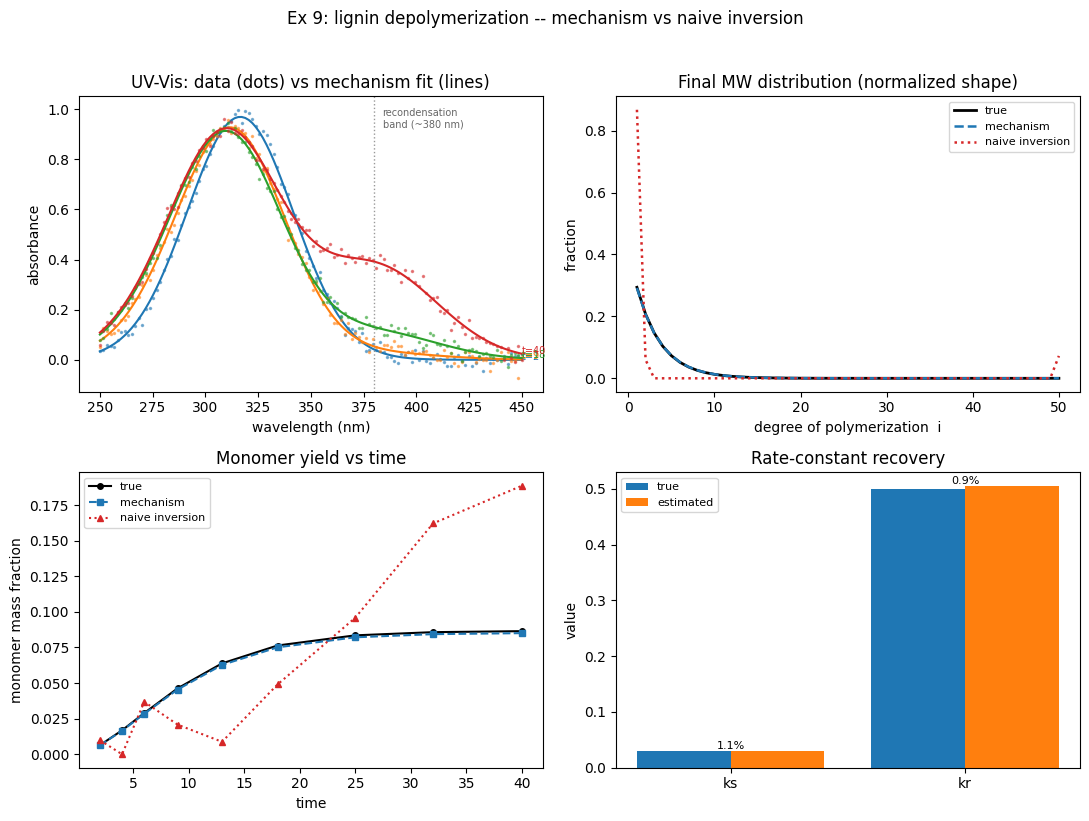

In [10]:
import matplotlib.pyplot as plt

# Mechanism reconstruction of the UV-Vis series from the fitted state history.
A_fit = np.asarray(observe(jnp.asarray(ro.state_history), ro.P))


def _shape(N):
    return N[-1] / max(N[-1].sum(), 1e-12)


fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) UV-Vis: data (dots) vs mechanism fit (lines) at a few observation times.
for s in (0, 3, 5, 8):
    line, = ax[0, 0].plot(LAM, A_fit[s], lw=1.5)
    ax[0, 0].plot(LAM, A_data[s], ls='', marker='.', ms=3, alpha=0.5,
                  color=line.get_color())
    ax[0, 0].annotate(f't={T_OBS[s]:.0f}', (LAM[-1], A_fit[s, -1]),
                      fontsize=7, color=line.get_color())
ax[0, 0].axvline(380, color='0.6', ls=':', lw=1)
ax[0, 0].text(384, ax[0, 0].get_ylim()[1] * 0.88, 'recondensation\nband (~380 nm)',
              fontsize=7, color='0.4')
ax[0, 0].set(title='UV-Vis: data (dots) vs mechanism fit (lines)',
             xlabel='wavelength (nm)', ylabel='absorbance')

# (b) Final molecular-weight distribution: true / mechanism / naive.
ax[0, 1].plot(IVEC, _shape(N_true), 'k-', lw=2, label='true')
ax[0, 1].plot(IVEC, _shape(N_fit), 'C0--', lw=1.8, label='mechanism')
ax[0, 1].plot(IVEC, _shape(N_naive), 'C3:', lw=1.8, label='naive inversion')
ax[0, 1].set(title='Final MW distribution (normalized shape)',
             xlabel='degree of polymerization  i', ylabel='fraction')
ax[0, 1].legend(fontsize=8)

# (c) Monomer yield over time: the naive inversion overestimates it.
ax[1, 0].plot(T_OBS, mono_true, 'k-o', ms=4, label='true')
ax[1, 0].plot(T_OBS, mono_fit, 'C0--s', ms=4, label='mechanism')
ax[1, 0].plot(T_OBS, mono_naive, 'C3:^', ms=4, label='naive inversion')
ax[1, 0].set(title='Monomer yield vs time',
             xlabel='time', ylabel='monomer mass fraction')
ax[1, 0].legend(fontsize=8)

# (d) Rate-constant recovery.
names = ['ks', 'kr']
tv = [KS_TRUE, KR_TRUE]
ev = [ro.P['ks'], ro.P['kr']]
x = np.arange(len(names))
ax[1, 1].bar(x - 0.2, tv, 0.4, label='true')
ax[1, 1].bar(x + 0.2, ev, 0.4, label='estimated')
for xi, (t, e) in enumerate(zip(tv, ev)):
    ax[1, 1].annotate(f'{abs(e - t) / t * 100:.1f}%', (xi, max(t, e)),
                      ha='center', va='bottom', fontsize=8)
ax[1, 1].set_xticks(x)
ax[1, 1].set_xticklabels(names)
ax[1, 1].set(title='Rate-constant recovery', ylabel='value')
ax[1, 1].legend(fontsize=8)

fig.suptitle('Ex 9: lignin depolymerization -- mechanism vs naive inversion',
             y=1.02)
fig.tight_layout()